# Redes Neurais Recorrentes (RNN) aplicadas a Séries Temporais

Implementação e avaliação de modelos baseados em **Redes Neurais Recorrentes (RNNs)** para a previsão de séries temporais.

### Etapas:
1. **Preparação dos Dados:** Estruturação das janelas temporais no formato tridimensional **NTC** (*Amostras, Passos Temporais, Canais*).
2. **Modelagem:** Construção de arquiteturas com camadas recorrentes simples (`SimpleRNN`), explorando abordagens *Sequence-to-Vector* e empilhamento de camadas.
3. **Treinamento e Avaliação:** Ajuste dos modelos, monitoramento das métricas de erro e análise das previsões frente aos dados reais.

In [2]:
import pandas as pd

# Configuração para reprodutibilidade
SEED = 42

# Carregamento do dataset
DATASET_PATH = "../data/team-time-series-10000.xlsx"

df = pd.read_excel(DATASET_PATH)

print(f"Seed definida: {SEED}")
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")

display(df.head())

Seed definida: 42
Dimensões do dataset: 289264 linhas e 108 colunas


,match_id,timestep,vencedor,blue_championStats.abilityHaste,blue_championStats.abilityPower,blue_championStats.armor,blue_championStats.attackDamage,blue_championStats.health,blue_currentGold,blue_damageStats.magicDamageDone,...,diff_kills,diff_deaths,diff_assists,diff_dragons,diff_elder_dragons,diff_barons,diff_rift_heralds,diff_atakhan,diff_towers_destroyed,diff_inhibitors_destroyed
0,BR1_3258230874,0,200,0,0,151,278,3080,2100,0,...,0,0,0,0,0,0,0,0,0,0
1,BR1_3258230874,1,200,0,9,151,318,3559,0,15,...,0,0,0,0,0,0,0,0,0,0
2,BR1_3258230874,2,200,0,9,166,329,3135,1846,304,...,1,-1,1,0,0,0,0,0,0,0
3,BR1_3258230874,3,200,0,9,190,375,3290,1776,1777,...,1,-1,1,0,0,0,0,0,0,0
4,BR1_3258230874,4,200,0,9,217,388,3159,3219,3237,...,1,-1,1,0,0,0,0,0,0,0


In [3]:
# Filtragem dos primeiros 20 minutos (inclusive)
df_filtrado = df[df["timestep"].between(0, 20)].copy()

print(f"Dimensões após filtragem: {df_filtrado.shape}")
print(f"Partidas encontradas: {df_filtrado['match_id'].nunique()}")
print(f"Timesteps encontrados: {sorted(df_filtrado['timestep'].unique())}")

display(df_filtrado.head())

Dimensões após filtragem: (210000, 108)
Partidas encontradas: 10000
Timesteps encontrados: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


,match_id,timestep,vencedor,blue_championStats.abilityHaste,blue_championStats.abilityPower,blue_championStats.armor,blue_championStats.attackDamage,blue_championStats.health,blue_currentGold,blue_damageStats.magicDamageDone,...,diff_kills,diff_deaths,diff_assists,diff_dragons,diff_elder_dragons,diff_barons,diff_rift_heralds,diff_atakhan,diff_towers_destroyed,diff_inhibitors_destroyed
0,BR1_3258230874,0,200,0,0,151,278,3080,2100,0,...,0,0,0,0,0,0,0,0,0,0
1,BR1_3258230874,1,200,0,9,151,318,3559,0,15,...,0,0,0,0,0,0,0,0,0,0
2,BR1_3258230874,2,200,0,9,166,329,3135,1846,304,...,1,-1,1,0,0,0,0,0,0,0
3,BR1_3258230874,3,200,0,9,190,375,3290,1776,1777,...,1,-1,1,0,0,0,0,0,0,0
4,BR1_3258230874,4,200,0,9,217,388,3159,3219,3237,...,1,-1,1,0,0,0,0,0,0,0


In [4]:
# Identificação das colunas de entrada
feature_cols = [
    col for col in df_filtrado.columns
    if col.startswith(("blue_", "red_", "diff_"))
]

# Separação das características e do vencedor
X = df_filtrado[feature_cols]
y = df_filtrado["vencedor"]

print(f"Quantidade de características: {len(feature_cols)}")
print(f"Dimensões de X: {X.shape}")
print(f"Dimensões de y: {y.shape}")

print("\nDistribuição dos vencedores:")
print(y.value_counts())

Quantidade de características: 105
Dimensões de X: (210000, 105)
Dimensões de y: (210000,)

Distribuição dos vencedores:
vencedor
200    113379
100     96621
Name: count, dtype: int64


In [5]:
import numpy as np

# Ordenação cronológica dos registros
df_filtrado = df_filtrado.sort_values(
    by=["match_id", "timestep"]
).reset_index(drop=True)

# Recuperação das características após a ordenação
X = df_filtrado[feature_cols].to_numpy()

# Transformação: partidas × instantes × características
X = X.reshape(10000, 21, 105)

# Um único vencedor por partida
y = df_filtrado.groupby("match_id", sort=False)["vencedor"].first().to_numpy()

print(f"Dimensões de X: {X.shape}")
print(f"Dimensões de y: {y.shape}")

Dimensões de X: (10000, 21, 105)
Dimensões de y: (10000,)


In [6]:
# Índices para divisão cronológica
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Separação dos conjuntos
X_train, y_train = X[:train_end], y[:train_end]

X_val, y_val = X[train_end:val_end], y[train_end:val_end]

X_test, y_test = X[val_end:], y[val_end:]

print("Treinamento:", X_train.shape, y_train.shape)
print("Validação:", X_val.shape, y_val.shape)
print("Teste:", X_test.shape, y_test.shape)

Treinamento: (7000, 21, 105) (7000,)
Validação: (1500, 21, 105) (1500,)
Teste: (1500, 21, 105) (1500,)


In [7]:
from sklearn.preprocessing import StandardScaler

# Inicialização do normalizador
scaler = StandardScaler()

# Transformação temporária para duas dimensões
X_train_2d = X_train.reshape(-1, 105)

# Ajuste e normalização do treinamento
X_train_scaled = scaler.fit_transform(X_train_2d)

# Normalização da validação e do teste usando os parâmetros do treinamento
X_val_scaled = scaler.transform(X_val.reshape(-1, 105))
X_test_scaled = scaler.transform(X_test.reshape(-1, 105))

# Recuperação do formato tridimensional
X_train = X_train_scaled.reshape(7000, 21, 105)
X_val = X_val_scaled.reshape(1500, 21, 105)
X_test = X_test_scaled.reshape(1500, 21, 105)

print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treinamento: (7000, 21, 105)
Validação: (1500, 21, 105)
Teste: (1500, 21, 105)


In [8]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configuração para reprodutibilidade
tf.keras.utils.set_random_seed(SEED)

print(f"TensorFlow: {tf.__version__}")

TensorFlow: 2.21.0


In [10]:
# Dimensões da entrada
num_features = X_train.shape[2]
win_size = X_train.shape[1]

# Construção da RNN
model_rnn = keras.Sequential([
    layers.Input(shape=(win_size, num_features)),

    # Primeira camada recorrente (retorna a sequência completa para a próxima camada)
    layers.SimpleRNN(
        units=32,
        return_sequences=True
    ),

    # Segunda camada recorrente (retorna apenas o último estado oculto: Seq2Vec)
    layers.SimpleRNN(
        units=64,
        return_sequences=False
    ),

    # Camada totalmente conectada
    layers.Dense(64, activation="relu"),

    # Saída para classificação binária
    layers.Dense(1, activation="sigmoid")

], name="RNN_LeagueOfLegends")

model_rnn.summary()

Model: "RNN_LeagueOfLegends"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 21, 32)         │         4,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,849 (58.00 KB)

 Trainable params: 14,849 (58.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Conversão dos rótulos para classificação binária
y_train = (y_train == 200).astype("float32")
y_val = (y_val == 200).astype("float32")
y_test = (y_test == 200).astype("float32")

print("Distribuição dos rótulos de treinamento:")
print(pd.Series(y_train).value_counts().sort_index())

Distribuição dos rótulos de treinamento:
0.0    3223
1.0    3777
Name: count, dtype: int64


In [12]:
# Compilação da RNN
model_rnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.002),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Interrompe o treinamento caso a validação não melhore
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [13]:
# Treinamento da RNN
history_rnn = model_rnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.7550 - loss: 0.5049 - val_accuracy: 0.7727 - val_loss: 0.4856
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7713 - loss: 0.4743 - val_accuracy: 0.7673 - val_loss: 0.4809
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7759 - loss: 0.4653 - val_accuracy: 0.7713 - val_loss: 0.4765
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7836 - loss: 0.4526 - val_accuracy: 0.7653 - val_loss: 0.4759
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7880 - loss: 0.4406 - val_accuracy: 0.7660 - val_loss: 0.4869
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7907 - loss: 0.4315 - val_accuracy: 0.7540 - val_loss: 0.4988
Epoch 7/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7977 - loss: 0.4154 - val_accuracy: 0.7540 - val_loss: 0.5057


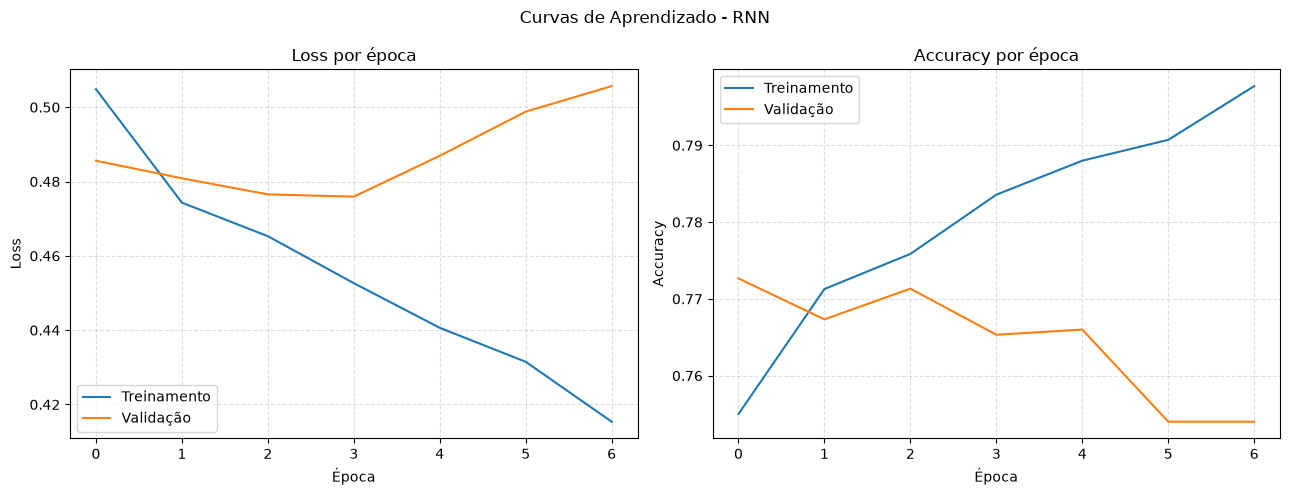

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva de Loss
axes[0].plot(
    history_rnn.history["loss"],
    label="Treinamento"
)

axes[0].plot(
    history_rnn.history["val_loss"],
    label="Validação"
)

axes[0].set_title("Loss por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Curva de Accuracy
axes[1].plot(
    history_rnn.history["accuracy"],
    label="Treinamento"
)

axes[1].plot(
    history_rnn.history["val_accuracy"],
    label="Validação"
)

axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.suptitle("Curvas de Aprendizado - RNN")
plt.tight_layout()
plt.show()

In [23]:
curvas = history_rnn.history

print("=== Curvas de aprendizado [RNN] ===")
print(f"Épocas: {list(range(1, len(curvas['loss']) + 1))}")
print(f"Loss - Treinamento: {[float(v) for v in curvas['loss']]}")
print(f"Loss - Validação: {[float(v) for v in curvas['val_loss']]}")
print(f"Accuracy - Treinamento: {[float(v) for v in curvas['accuracy']]}")
print(f"Accuracy - Validação: {[float(v) for v in curvas['val_accuracy']]}")

=== Curvas de aprendizado [RNN] ===
Épocas: [1, 2, 3, 4, 5, 6, 7]
Loss - Treinamento: [0.5048525929450989, 0.47431716322898865, 0.4652867615222931, 0.4526435434818268, 0.44062480330467224, 0.43148431181907654, 0.4153576195240021]
Loss - Validação: [0.4856012463569641, 0.480875700712204, 0.4765447974205017, 0.4759320914745331, 0.48694169521331787, 0.49882611632347107, 0.505685567855835]
Accuracy - Treinamento: [0.7549999952316284, 0.7712857127189636, 0.775857150554657, 0.7835714221000671, 0.7879999876022339, 0.7907142639160156, 0.7977142930030823]
Accuracy - Validação: [0.7726666927337646, 0.7673333287239075, 0.7713333368301392, 0.765333354473114, 0.765999972820282, 0.7540000081062317, 0.7540000081062317]


In [15]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Probabilidades previstas pela RNN
y_val_prob = model_rnn.predict(X_val)

# Conversão das probabilidades em classes (limiar 0.5)
y_val_pred = (y_val_prob >= 0.5).astype(int).ravel()

# Cálculo das métricas
accuracy = accuracy_score(y_val, y_val_pred)
f1_macro = f1_score(y_val, y_val_pred, average="macro")
balanced_acc = balanced_accuracy_score(y_val, y_val_pred)

print(f"Accuracy:          {accuracy:.4f}")
print(f"F1 Macro:          {f1_macro:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_val_pred))

47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Accuracy:          0.7653
F1 Macro:          0.7613
Balanced Accuracy: 0.7598

Matriz de confusão:
[[476 204]
 [148 672]]


In [16]:
# Probabilidades previstas pela RNN no conjunto de teste
y_test_prob = model_rnn.predict(X_test)

# Conversão das probabilidades em classes (limiar 0.5)
y_test_pred = (y_test_prob >= 0.5).astype(int).ravel()

# Cálculo das métricas
accuracy_test = accuracy_score(y_test, y_test_pred)
f1_macro_test = f1_score(y_test, y_test_pred, average="macro")
balanced_acc_test = balanced_accuracy_score(y_test, y_test_pred)

print("=" * 50)
print("AVALIAÇÃO - RNN (CONJUNTO DE TESTE)")
print("=" * 50)

print(f"Accuracy:          {accuracy_test:.4f}")
print(f"F1 Macro:          {f1_macro_test:.4f}")
print(f"Balanced Accuracy: {balanced_acc_test:.4f}")

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
AVALIAÇÃO - RNN (CONJUNTO DE TESTE)
Accuracy:          0.7627
F1 Macro:          0.7603
Balanced Accuracy: 0.7595


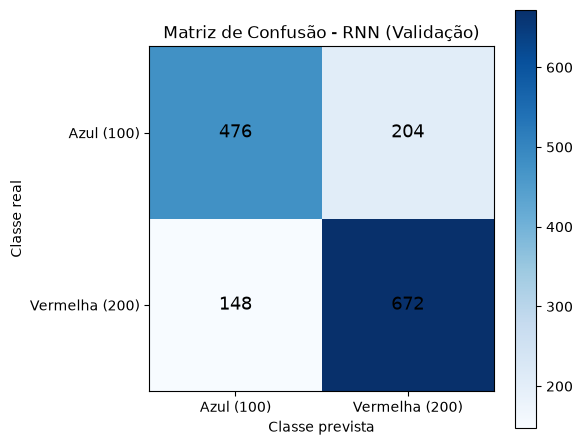

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calcula a matriz de confusão
cm = confusion_matrix(y_val, y_val_pred)

# Visualização
plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Matriz de Confusão - RNN (Validação)")
plt.colorbar()

# Rótulos dos eixos
classes = ["Azul (100)", "Vermelha (200)"]

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")

# Valores dentro das células
for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=13
        )

plt.tight_layout()
plt.show()

## Comparação entre os modelos

A seguir, os resultados da RNN serão comparados com os modelos anteriores (Baseline, Random Forest, XGBoost e CNN-1D) utilizando as métricas **Accuracy**, **F1 Macro** e **Balanced Accuracy**.

A análise verificará se a modelagem sequencial dos estados das partidas supera as abordagens anteriores. A comparação ocorrerá inicialmente no conjunto de validação e, em seguida, no conjunto de teste para avaliar a capacidade de generalização do modelo.

In [18]:
import pandas as pd

# Resultados do Baseline
resultados_baseline = {
    "Accuracy": 0.5347,
    "F1 Macro": 0.3484,
    "Balanced Accuracy": 0.5000
}

# Resultados do Random Forest
resultados_rf = {
    "validacao": {
        "Accuracy": 0.7753,
        "F1 Macro": 0.7726,
        "Balanced Accuracy": 0.7718
    },
    "teste": {
        "Accuracy": 0.7507,
        "F1 Macro": 0.7493,
        "Balanced Accuracy": 0.7492
    }
}

# Resultados do XGBoost
resultados_xgb = {
    "validacao": {
        "Accuracy": 0.7693,
        "F1 Macro": 0.7665,
        "Balanced Accuracy": 0.7657
    },
    "teste": {
        "Accuracy": 0.7547,
        "F1 Macro": 0.7529,
        "Balanced Accuracy": 0.7525
    }
}

# Resultados da CNN-1D
resultados_cnn = {
    "validacao": {
        "Accuracy": 0.7747,          
        "F1 Macro": 0.7694,          
        "Balanced Accuracy": 0.7673  
    },
    "teste": {
        "Accuracy": 0.7647,
        "F1 Macro": 0.7616,
        "Balanced Accuracy": 0.7604
    }
}

# Resultados da RNN
resultados_rnn = {
    "validacao": {
        "Accuracy": accuracy,
        "F1 Macro": f1_macro,
        "Balanced Accuracy": balanced_acc
    },
    "teste": {
        "Accuracy": accuracy_test,
        "F1 Macro": f1_macro_test,
        "Balanced Accuracy": balanced_acc_test
    }
}

print("Resultados dos cinco modelos armazenados!")

Resultados dos cinco modelos armazenados!


In [19]:
# Resultados de validação
dados_validacao = {
    "Baseline": resultados_baseline,
    "Random Forest": resultados_rf["validacao"],
    "XGBoost": resultados_xgb["validacao"],
    "CNN-1D": resultados_cnn["validacao"],
    "RNN": resultados_rnn["validacao"]
}

df_validacao = pd.DataFrame(dados_validacao).T

# Resultados de teste
dados_teste = {
    "Baseline": resultados_baseline,
    "Random Forest": resultados_rf["teste"],
    "XGBoost": resultados_xgb["teste"],
    "CNN-1D": resultados_cnn["teste"],
    "RNN": resultados_rnn["teste"]
}

df_teste = pd.DataFrame(dados_teste).T

print("=" * 60)
print("COMPARAÇÃO DOS MODELOS - VALIDAÇÃO")
print("=" * 60)
display(df_validacao.round(4))

print("\n" + "=" * 60)
print("COMPARAÇÃO DOS MODELOS - TESTE")
print("=" * 60)
display(df_teste.round(4))

# Identifica o melhor modelo em cada conjunto
melhor_validacao = df_validacao["F1 Macro"].idxmax()
melhor_teste = df_teste["F1 Macro"].idxmax()

print("\nMINI-RELATÓRIO COMPARATIVO")
print("-" * 60)

print(
    f"Melhor modelo na validação: {melhor_validacao} "
    f"(F1 Macro: {df_validacao.loc[melhor_validacao, 'F1 Macro']:.4f})"
)

print(
    f"Melhor modelo no teste: {melhor_teste} "
    f"(F1 Macro: {df_teste.loc[melhor_teste, 'F1 Macro']:.4f})"
)

COMPARAÇÃO DOS MODELOS - VALIDAÇÃO


,Accuracy,F1 Macro,Balanced Accuracy
Baseline,0.5347,0.3484,0.5000
Random Forest,0.7753,0.7726,0.7718
XGBoost,0.7693,0.7665,0.7657
CNN-1D,0.7747,0.7694,0.7673
RNN,0.7653,0.7613,0.7598



COMPARAÇÃO DOS MODELOS - TESTE


,Accuracy,F1 Macro,Balanced Accuracy
Baseline,0.5347,0.3484,0.5000
Random Forest,0.7507,0.7493,0.7492
XGBoost,0.7547,0.7529,0.7525
CNN-1D,0.7647,0.7616,0.7604
RNN,0.7627,0.7603,0.7595



MINI-RELATÓRIO COMPARATIVO
------------------------------------------------------------
Melhor modelo na validação: Random Forest (F1 Macro: 0.7726)
Melhor modelo no teste: CNN-1D (F1 Macro: 0.7616)


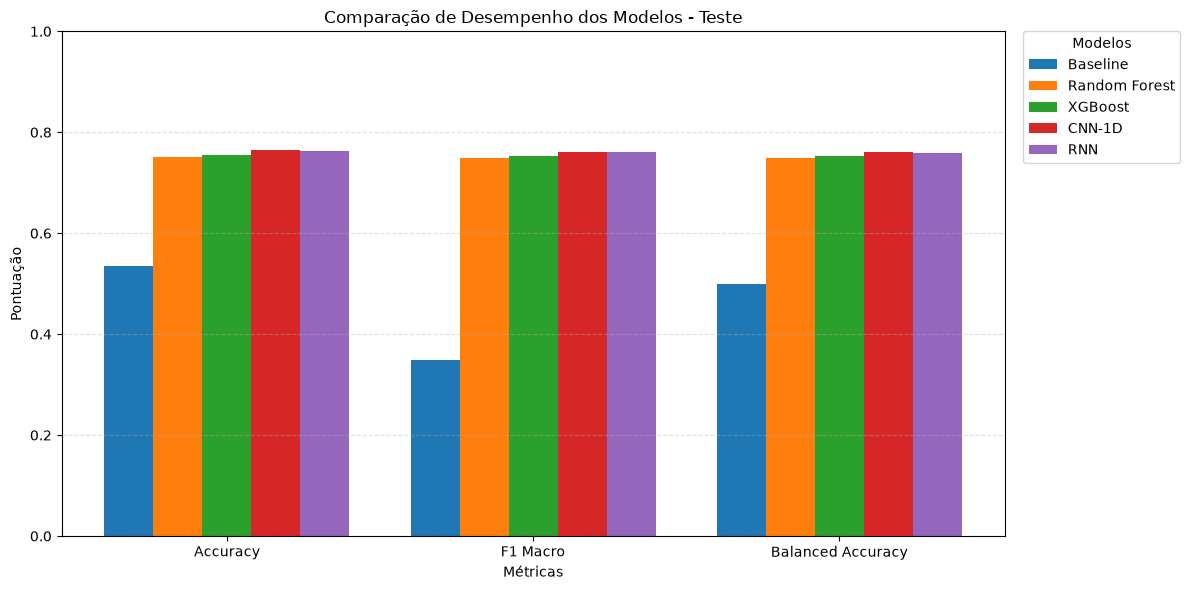

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Métricas
metricas = ["Accuracy", "F1 Macro", "Balanced Accuracy"]

modelos = df_teste.index.tolist()

x = np.arange(len(metricas))
largura = 0.16

plt.figure(figsize=(12, 6))

for i, modelo in enumerate(modelos):
    valores = df_teste.loc[modelo, metricas].values

    plt.bar(
        x + (i - 2) * largura,
        valores,
        largura,
        label=modelo
    )

plt.title("Comparação de Desempenho dos Modelos - Teste")
plt.ylabel("Pontuação")
plt.xlabel("Métricas")
plt.xticks(x, metricas)
plt.ylim(0, 1)

# Legenda posicionada fora da área do gráfico (à direita)
plt.legend(
    title="Modelos",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [21]:
cm_teste = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

print("Matriz de confusão — Teste - RNN")
print("Linhas: valores reais | Colunas: previsões")
print("Ordem das classes: Equipe Azul (100), Equipe Vermelha (200)")
print(cm_teste)

Matriz de confusão — Teste - RNN
Linhas: valores reais | Colunas: previsões
Ordem das classes: Equipe Azul (100), Equipe Vermelha (200)
[[498 200]
 [156 646]]
